# Esplorazione iniziale di TEM-1

Questo notebook estrae embedding del wild type con ESM-2 150M ed esplora i dati DMS. Non implementa un predittore supervisionato delle varianti. Per metodo, benchmark e istruzioni fare riferimento al [README](README.md).

Avviare dalla radice di `Bioscience-PLM`: le celle usano `TEM1.fasta` e `proteingym_substitutions.zip` nella directory corrente. Il FASTA viene scaricato e riscritto; lo ZIP viene scaricato soltanto se assente. L’inferenza esplorativa usa CPU e il checkpoint non è fissato a un commit: per il confronto riproducibile usare la pipeline descritta nel README.


In [3]:
import torch
from transformers import AutoTokenizer, EsmModel
from Bio import SeqIO

import requests
import os
import pandas as pd
import zipfile

In [4]:
model_name = "facebook/esm2_t30_150M_UR50D"

# Tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Modello ESM-2 150M
model = EsmModel.from_pretrained(model_name)

# Modalità valutazione
model.eval()

print("Model loaded!")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t30_150M_UR50D and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model loaded!
Parameters: 148,138,841


In [5]:
url = "https://rest.uniprot.org/uniprotkb/P62593.fasta"

response = requests.get(url)
response.raise_for_status()

with open("TEM1.fasta", "w") as f:
    f.write(response.text)

print(response.text)

>sp|P62593|BLAT_ECOLX Beta-lactamase TEM OS=Escherichia coli OX=562 GN=bla PE=1 SV=1
MSIQHFRVALIPFFAAFCLPVFAHPETLVKVKDAEDQLGARVGYIELDLNSGKILESFRP
EERFPMMSTFKVLLCGAVLSRVDAGQEQLGRRIHYSQNDLVEYSPVTEKHLTDGMTVREL
CSAAITMSDNTAANLLLTTIGGPKELTAFLHNMGDHVTRLDRWEPELNEAIPNDERDTTM
PAAMATTLRKLLTGELLTLASRQQLIDWMEADKVAGPLLRSALPAGWFIADKSGAGERGS
RGIIAALGPDGKPSRIVVIYTTGSQATMDERNRQIAEIGASLIKHW



In [6]:
record = SeqIO.read("TEM1.fasta", "fasta")
sequence = str(record.seq)

print("Sequence length:", len(sequence))

Sequence length: 286


In [7]:
device = "cpu"

inputs = tokenizer(
    sequence,
    return_tensors="pt"
)

inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

embeddings = outputs.last_hidden_state

print("Embedding shape:", embeddings.shape)

Embedding shape: torch.Size([1, 288, 640])


In [8]:
url = (
    "https://marks.hms.harvard.edu/proteingym/"
    "ProteinGym_v1.3/DMS_ProteinGym_substitutions.zip"
)

zip_path = "proteingym_substitutions.zip"

if not os.path.exists(zip_path):
    response = requests.get(url, stream=True)
    response.raise_for_status()

    with open(zip_path, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024*1024):
            if chunk:
                f.write(chunk)

print("Download completato!")

Download completato!


In [9]:
with zipfile.ZipFile(zip_path, "r") as z:

    files = z.namelist()

    candidates = [
        f for f in files
        if "BLAT_ECOLX" in f.upper()
        or "TEM1" in f.upper()
        or "TEM-1" in f.upper()
    ]

    for f in candidates:
        print(f)

DMS_ProteinGym_substitutions/BLAT_ECOLX_Jacquier_2013.csv
DMS_ProteinGym_substitutions/BLAT_ECOLX_Firnberg_2014.csv
DMS_ProteinGym_substitutions/BLAT_ECOLX_Deng_2012.csv
DMS_ProteinGym_substitutions/BLAT_ECOLX_Stiffler_2015.csv


In [10]:
file = "DMS_ProteinGym_substitutions/BLAT_ECOLX_Stiffler_2015.csv"

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open(file) as f:
        df = pd.read_csv(f)

print("Numero varianti:", len(df))
print("\nColonne:")
print(df.columns.tolist())

df.head()

Numero varianti: 4996

Colonne:
['mutant', 'mutated_sequence', 'DMS_score', 'DMS_score_bin']


,mutant,mutated_sequence,DMS_score,DMS_score_bin
0,H24C,MSIQHFRVALIPFFAAFCLPVFACPETLVKVKDAEDQLGARVGYIE...,-0.418260,1
1,H24Y,MSIQHFRVALIPFFAAFCLPVFAYPETLVKVKDAEDQLGARVGYIE...,-0.885025,1
2,H24W,MSIQHFRVALIPFFAAFCLPVFAWPETLVKVKDAEDQLGARVGYIE...,-1.347586,0
3,H24V,MSIQHFRVALIPFFAAFCLPVFAVPETLVKVKDAEDQLGARVGYIE...,-0.026874,1
4,H24T,MSIQHFRVALIPFFAAFCLPVFATPETLVKVKDAEDQLGARVGYIE...,-0.067188,1


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4996 entries, 0 to 4995
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   mutant            4996 non-null   str    
 1   mutated_sequence  4996 non-null   str    
 2   DMS_score         4996 non-null   float64
 3   DMS_score_bin     4996 non-null   int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 156.3 KB


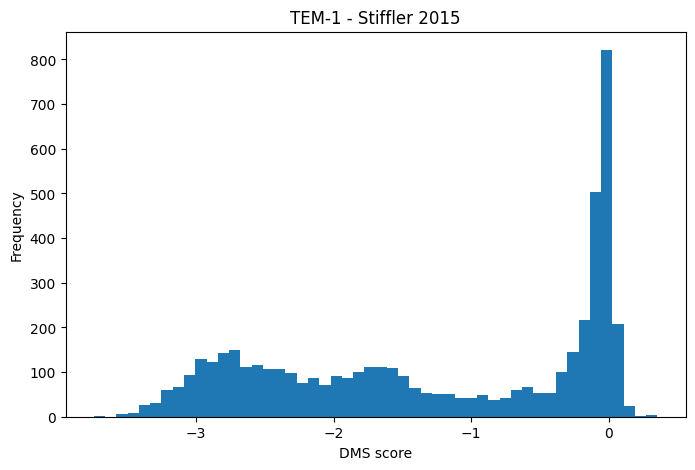

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(df["DMS_score"].dropna(), bins=50)

plt.xlabel("DMS score")
plt.ylabel("Frequency")
plt.title("TEM-1 - Stiffler 2015")

plt.show()

In [13]:
import re
import numpy as np
import pandas as pd

# Una mutazione è sempre nel formato <lettera WT><posizione><lettera nuova>, es. "H24V".
# Un multi-mutante contiene più di una mutazione nella stessa stringa, es. "H24VG102A".
MUT_RE = re.compile(r"([A-Z])(\d+)([A-Z])")

def parse_mutant(s):
    muts = MUT_RE.findall(str(s))
    if len(muts) == 0:
        return None
    # lista di (wt, posizione, nuovo) per ogni mutazione nella variante
    return [(wt, int(pos), new) for wt, pos, new in muts]

df["mutations"] = df["mutant"].apply(parse_mutant)
df["n_mutations"] = df["mutations"].apply(lambda m: len(m) if m else 0)

print("Righe totali:", len(df))
print("Single-mutant:", (df["n_mutations"] == 1).sum())
print("Multi-mutant :", (df["n_mutations"] > 1).sum())
print("Non parse    :", df["n_mutations"].sum() == 0 if df["n_mutations"].eq(0).any() else 0)

Righe totali: 4996
Single-mutant: 4996
Multi-mutant : 0
Non parse    : 0


In [18]:
def check_row(row):
    seq = row["mutated_sequence"]
    for wt, pos, new in row["mutations"]:
        # la posizione nella sequenza mutata deve contenere l'aminoacido NUOVO
        if seq[pos - 1] != new:
            return False
    return True

ok = df[df["n_mutations"] == 1].apply(check_row, axis=1)
print("Single-mutant coerenti con mutated_sequence:", ok.sum(), "/", len(ok))

# Ricostruisco la sequenza wild-type del DMS: sostituisco indietro l'aminoacido
# in ogni variante; tutte le righe devono dare la STESSA sequenza.
def to_wildtype(row):
    seq = list(row["mutated_sequence"])
    for wt, pos, new in row["mutations"]:
        seq[pos - 1] = wt
    return "".join(seq)

wt_seqs = df["n_mutations"].eq(1) & ok  # maschera di righe valide
dms_wt = df[wt_seqs].apply(to_wildtype, axis=1).unique()
print("Sequenze wild-type uniche ricostruite:", len(dms_wt))
dms_wt_sequence = dms_wt[0]

# Confronto con il FASTA che hai già (record/sequence della cella precedente)
print("Lunghezza DMS wt:", len(dms_wt_sequence))
print("Lunghezza FASTA :", len(sequence))
print("Identiche:", dms_wt_sequence == sequence)

if dms_wt_sequence != sequence:
    # Se differiscono, quella giusta per lavorare è dms_wt_sequence:
    # è la numeratura con cui sono stati misurati i DMS_score.
    print("Differenza: userò la sequenza DMS come riferimento.")
    sequence = dms_wt_sequence

Single-mutant coerenti con mutated_sequence: 4996 / 4996
Sequenze wild-type uniche ricostruite: 1
Lunghezza DMS wt: 286
Lunghezza FASTA : 286
Identiche: True


In [19]:
single = df[(df["n_mutations"] == 1) & wt_seqs].copy()

# Espando la singola mutazione in colonne: wt_aa, position, mut_aa
single["wt_aa"]  = single["mutations"].str[0].str[0]
single["position"] = single["mutations"].str[0].str[1]
single["mut_aa"] = single["mutations"].str[0].str[2]

single = single.dropna(subset=["DMS_score"]).reset_index(drop=True)

print("Single-mutanti con score validi:", len(single))
print("Posizioni distinte:", single["position"].nunique())
print("\nVarianti per posizione (riassunto):")
per_pos = single["position"].value_counts()
print(per_pos.describe())

Single-mutanti con score validi: 4996
Posizioni distinte: 263

Varianti per posizione (riassunto):
count    263.000000
mean      18.996198
std        0.061663
min       18.000000
25%       19.000000
50%       19.000000
75%       19.000000
max       19.000000
Name: count, dtype: float64


In [20]:
from sklearn.model_selection import GroupKFold

# Il gruppo è la posizione: se una posizione è nel test, TUTTE le sue
# varianti sono nel test. GroupKFold lo garantisce.
X_groups = single["position"].to_numpy()

gkf = GroupKFold(n_splits=5)
fold = np.full(len(single), -1)
for k, (_, test_idx) in enumerate(gkf.split(single, groups=X_groups)):
    fold[test_idx] = k

single["fold"] = fold

# Verifica che nessuna posizione sia in due fold
assert single.groupby("position")["fold"].nunique().eq(1).all()

print(single.groupby("fold").agg(
    n_varianti=("position", "size"),
    n_posizioni=("position", "nunique"),
))

# Salvo: questo file definisce l'esperimento, non si tocca più
single[["mutant", "wt_aa", "position", "mut_aa", "DMS_score", "fold"]].to_csv(
    "stiffler_single_folds.csv", index=False
)
print("Salvato stiffler_single_folds.csv")

      n_varianti  n_posizioni
fold                         
0           1007           53
1           1007           53
2           1006           53
3            988           52
4            988           52
Salvato stiffler_single_folds.csv


In [26]:
single

,mutant,mutated_sequence,DMS_score,DMS_score_bin,mutations,n_mutations,wt_aa,position,mut_aa,fold
0,H24C,MSIQHFRVALIPFFAAFCLPVFACPETLVKVKDAEDQLGARVGYIE...,-0.418260,1,"[(H, 24, C)]",1,H,24,C,2
1,H24Y,MSIQHFRVALIPFFAAFCLPVFAYPETLVKVKDAEDQLGARVGYIE...,-0.885025,1,"[(H, 24, Y)]",1,H,24,Y,2
2,H24W,MSIQHFRVALIPFFAAFCLPVFAWPETLVKVKDAEDQLGARVGYIE...,-1.347586,0,"[(H, 24, W)]",1,H,24,W,2
3,H24V,MSIQHFRVALIPFFAAFCLPVFAVPETLVKVKDAEDQLGARVGYIE...,-0.026874,1,"[(H, 24, V)]",1,H,24,V,2
4,H24T,MSIQHFRVALIPFFAAFCLPVFATPETLVKVKDAEDQLGARVGYIE...,-0.067188,1,"[(H, 24, T)]",1,H,24,T,2
...,...,...,...,...,...,...,...,...,...,...
4991,W286G,MSIQHFRVALIPFFAAFCLPVFAHPETLVKVKDAEDQLGARVGYIE...,-3.228429,0,"[(W, 286, G)]",1,W,286,G,0
4992,W286F,MSIQHFRVALIPFFAAFCLPVFAHPETLVKVKDAEDQLGARVGYIE...,-0.780425,1,"[(W, 286, F)]",1,W,286,F,0
4993,W286E,MSIQHFRVALIPFFAAFCLPVFAHPETLVKVKDAEDQLGARVGYIE...,-2.545852,0,"[(W, 286, E)]",1,W,286,E,0
4994,W286C,MSIQHFRVALIPFFAAFCLPVFAHPETLVKVKDAEDQLGARVGYIE...,-2.983762,0,"[(W, 286, C)]",1,W,286,C,0
